# Classificando a qualidade de vinhos com ML

A indústria vinícola possui grande relevância econômica e cultural em
diversos países. Tradicionalmente, a avaliação da qualidade de um vinho é realizada por especialistas, por meio de análises sensoriais, que consideram aspectos como aroma, sabor, acidez e equilíbrio. No entanto, esse processo pode ser subjetivo e demandar tempo, além de depender da experiência dos avaliadores.  

Com o avanço das técnicas de ciência de dados e aprendizado de máquina,
tornou-se possível utilizar dados físico-químicos obtidos durante a produção do vinho para auxiliar na previsão da qualidade final do produto. Dessa forma, modelos preditivos podem apoiar enólogos e produtores na tomada de decisão, permitindo ajustes no processo produtivo e contribuindo para a padronização da qualidade.  

Esta base de dados Wine Quality Dataset, disponível
publicamente no Kaggle, contém informações físico-químicas de diferentes amostras de vinho, como acidez, teor alcoólico, densidade e níveis de dióxido de enxofre. Cada amostra também possui uma nota de qualidade atribuída por especialistas, que será utilizada como variável alvo para o desenvolvimento de modelos de classificação.

## Objetivo  

Desenvolver um modelo capaz de identificar padrões nos dados físico-químicos e prever se um vinho pertence ou não ao grupo de alta qualidade, contribuindo para uma avaliação mais rápida, objetiva e baseada em dados.

## Variável target  

A variável de qualidade - "quality", será transformada em uma classificação binária, na qual vinhos com nota maior ou igual a 7 serão considerados de alta qualidade, enquanto vinhos com nota inferior a 7 serão classificados como de baixa ou média qualidade.  

A variável target será a classificação binária.

## Atributos

*   Acidez fixa (fixed acidity);
*   Acidez volátil (volatile acidity);
*   Ácido cítrico (citric acid);
*   Açúcar residual (residual sugar);
*   Cloretos (chlorides);
*   Dióxido de enxofre livre (free sulfur dioxide);
*   Dióxido de enxofre total (total sulfur dioxide);
*   Densidade (density);
*   pH;
*   Sulfatos (sulphates);
*   Teor alcoólico (alcohol);
*   Qualidade do vinho (quality).

# 1. Importação da base de dados e bibliotecas

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
sns.set_theme(style='whitegrid')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import export_graphviz
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, average_precision_score

from imblearn.over_sampling import SMOTE

In [87]:
PASTA_RESULTS = '../results'
df = pd.read_csv("WineQT.csv", sep=',')
os.makedirs(PASTA_RESULTS, exist_ok=True)

# 2. Pré-processamento dos dados

In [45]:
print('Quantidade de linhas e colunas: ', df.shape)
print('\n')
df.head()

Quantidade de linhas e colunas:  (1143, 13)




,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [47]:
# Retirar a variável Id

df = df.drop(columns='Id', errors='ignore')

### 2.1 Feature Engineering

In [48]:
# Variável target

def classificar_binario(nota):
  if nota >= 7:
    return 1
  else:
    return 0

df['quality_bin'] = df['quality'].apply(classificar_binario)

In [49]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,quality_bin
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


### 2.2 Análise dos dados nulos

In [50]:
import missingno as msno

<Axes: >

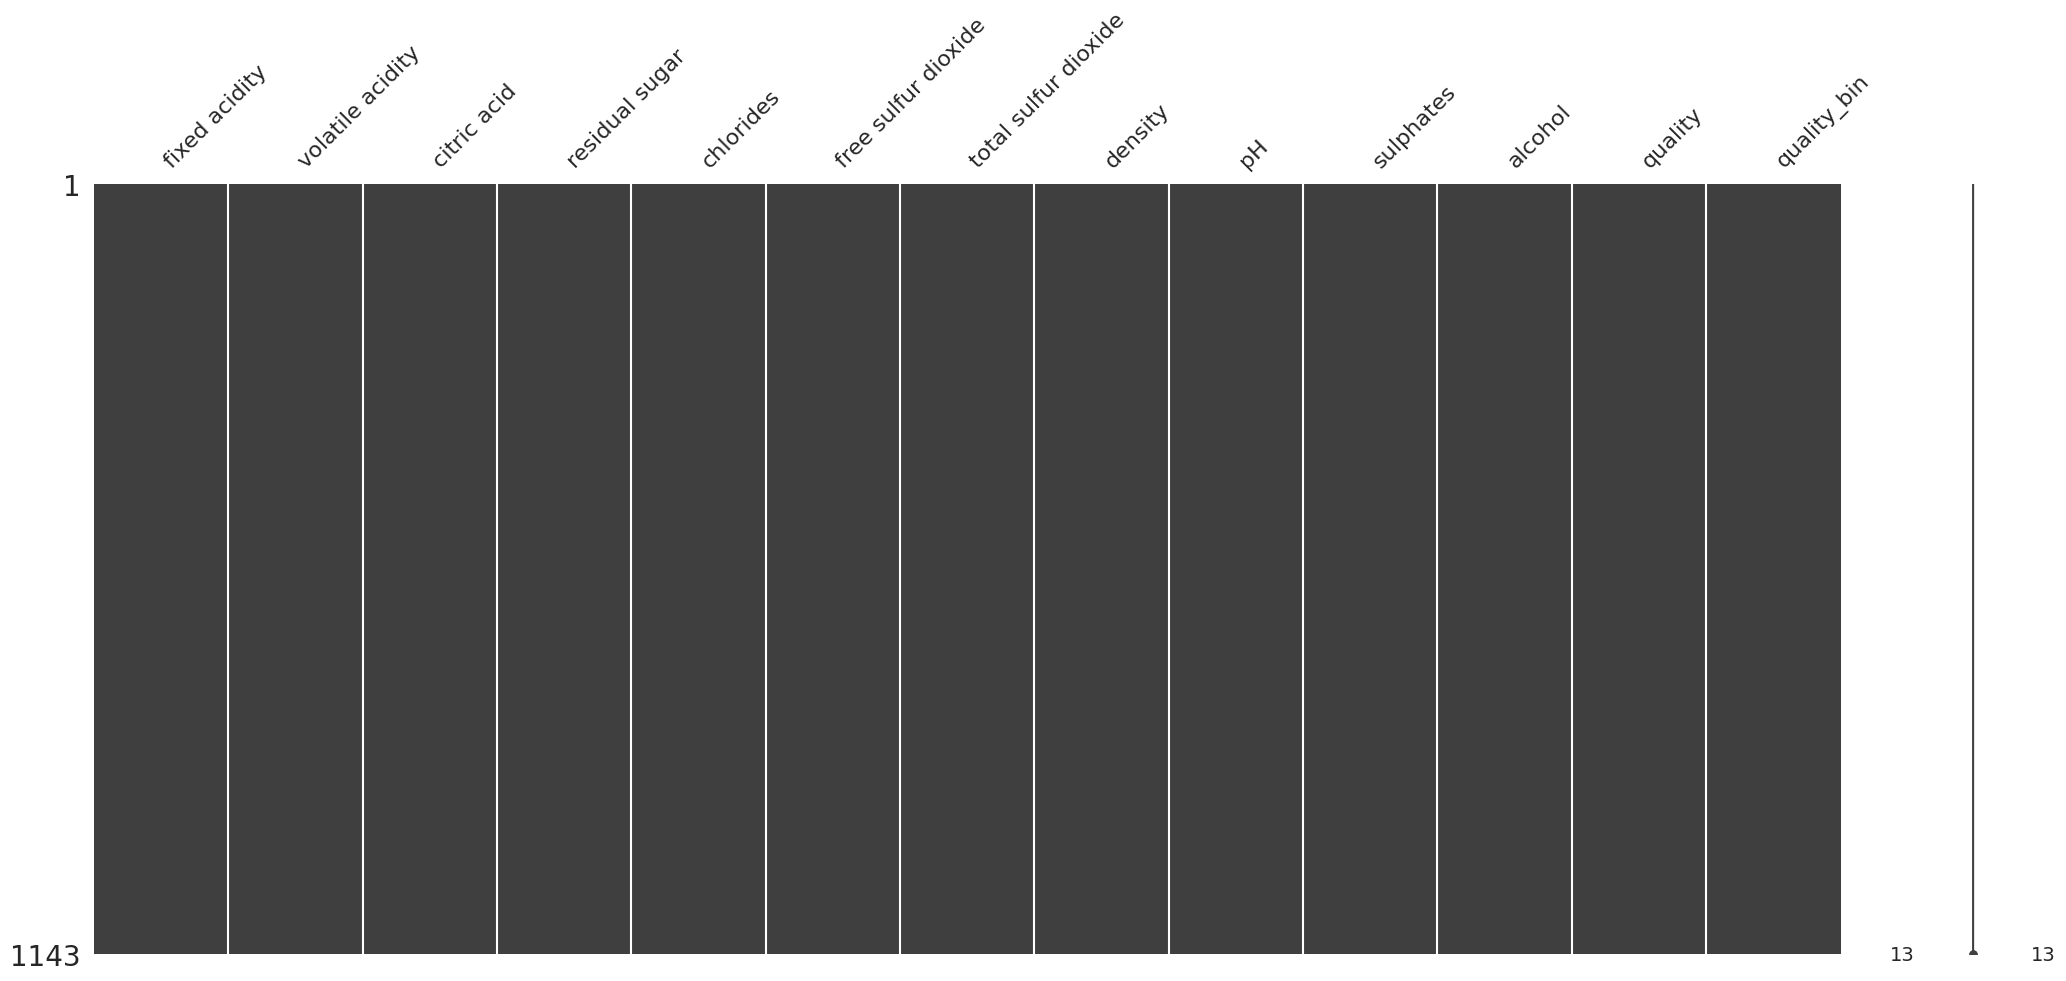

In [51]:
msno.matrix(df)

In [52]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


### 2.3 Análise dos dados duplicados

In [53]:
df.duplicated().sum()

np.int64(125)

In [54]:
df[df.duplicated()]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,quality_bin
4,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0
46,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.99620,3.41,0.39,10.9,5,0
64,8.6,0.490,0.28,1.90,0.110,20.0,136.0,0.99720,2.93,1.95,9.9,6,0
65,7.7,0.490,0.26,1.90,0.062,9.0,31.0,0.99660,3.39,0.64,9.6,5,0
71,8.1,0.545,0.18,1.90,0.080,13.0,35.0,0.99720,3.30,0.59,9.0,6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1076,7.5,0.380,0.57,2.30,0.106,5.0,12.0,0.99605,3.36,0.55,11.4,6,0
1113,7.8,0.600,0.26,2.00,0.080,31.0,131.0,0.99622,3.21,0.52,9.9,5,0
1114,7.8,0.600,0.26,2.00,0.080,31.0,131.0,0.99622,3.21,0.52,9.9,5,0
1116,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5,0


In [55]:
# Verificação das linhas duplicadas
cols_dados = [c for c in df.columns if c not in ['quality']]

dup_todas = df[df.duplicated(subset=cols_dados, keep=False)]
dup_todas = dup_todas.sort_values(cols_dados)

print('Linhas envolvidas em duplicação:', len(dup_todas))
print('Cópias extras: ', df.duplicated(subset=cols_dados).sum())
dup_todas.head()

Linhas envolvidas em duplicação: 239
Cópias extras:  125


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,quality_bin
96,5.2,0.34,0.0,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,6,0
98,5.2,0.34,0.0,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,6,0
949,6.0,0.50,0.0,1.4,0.057,15.0,26.0,0.99448,3.36,0.45,9.5,5,0
950,6.0,0.50,0.0,1.4,0.057,15.0,26.0,0.99448,3.36,0.45,9.5,5,0
951,6.0,0.50,0.0,1.4,0.057,15.0,26.0,0.99448,3.36,0.45,9.5,5,0


In [56]:
# Verificação da concentração das duplicatas

df[df.duplicated(subset=cols_dados, keep=False)]['quality'].value_counts().sort_index()

,count
quality,
5,96
6,100
7,41
8,2


Análise: Os dados duplicados estão concentrados nas notas 5, 6 e 7.

### 2.4 Análise dos dados ausentes

In [57]:
df.isna().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


 Análise: A base de dados não apresenta dados ausentes.

### 2.5 Análise dos valores iguais a zero

In [58]:
valores_zero = df.drop(['quality_bin'], axis=1)
(valores_zero == 0).sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,99
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [59]:
total = len(df)
print(total, 99 / total * 100)
print(pd.crosstab(df['quality_bin'], df['citric acid'] == 0, margins=True))

1143 8.661417322834646
citric acid  False  True   All
quality_bin                   
0              889    95   984
1              155     4   159
All           1044    99  1143


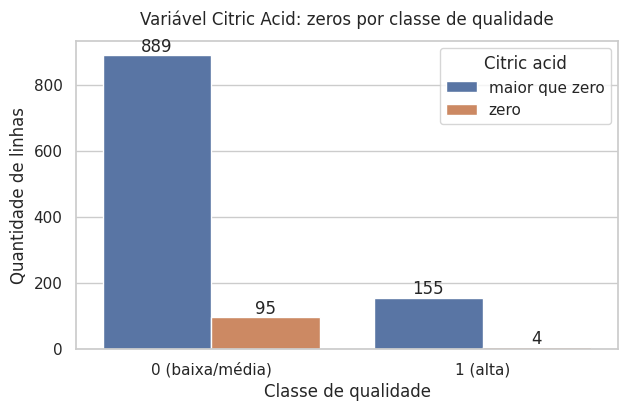

In [60]:
qtde_zero = (df['citric acid'].eq(0)
                .map({True: 'zero', False: 'maior que zero'})
                .rename('Citric acid'))

plt.figure(figsize=(7, 4))
ax = sns.countplot(x='quality_bin', hue=qtde_zero, data=df,
                   hue_order=['maior que zero', 'zero'])
ax.set_xticks([0, 1])
ax.set_xticklabels(['0 (baixa/média)', '1 (alta)'])
ax.set_xlabel('Classe de qualidade')
ax.set_ylabel('Quantidade de linhas')
ax.set_title('Variável Citric Acid: zeros por classe de qualidade', fontsize=12, pad=12)
for c in ax.containers:
    ax.bar_label(c)
plt.show()

**Decisão: as 99 linhas com valor zero em `citric acid` foram mantidas na base.**

Os zeros representam 8,7% das linhas e estão concentrados na classe de baixa/média qualidade (95 linhas, contra 4 na classe de alta qualidade). Optou-se por mantê-los por três motivos:

* não há indício de que sejam erros de registro, pois o zero é um valor possível para a variável;
* remover essas linhas reduziria a base e retiraria 4 vinhos da classe de alta qualidade, que já é a minoritária (159 vinhos);
* a exclusão alteraria pouco a análise: sem os zeros, a correlação do ácido cítrico com a alta qualidade passa de +0,25 para +0,24.

# 3. Análise Exploratória dos Dados (EDA)

### 3.1 Variável Target

In [61]:
df[['quality']].describe().T

,count,mean,std,min,25%,50%,75%,max
quality,1143.0,5.657043,0.805824,3.0,5.0,6.0,6.0,8.0


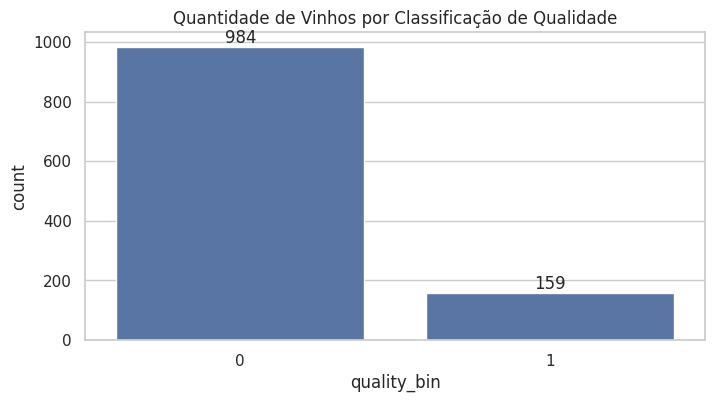

In [62]:
plt.figure(figsize=(8, 4))

ax = sns.countplot(data=df, x='quality_bin')
ax.set_xticks([0, 1])
ax.set_title('Quantidade de Vinhos por Classificação de Qualidade')
ax.bar_label(ax.containers[0])
plt.show()

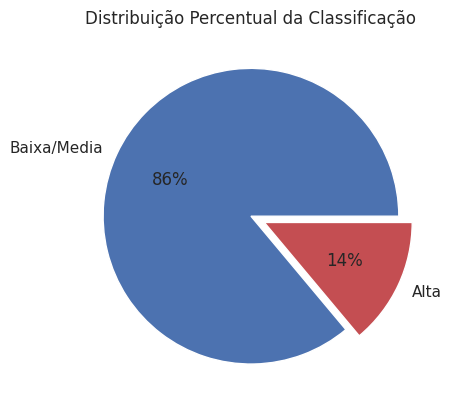

In [63]:
categorias = ["Baixa/Media", "Alta"]
plt.pie(df["quality_bin"].value_counts(), labels = categorias, autopct = "%.0f%%", explode= (0, 0.1), colors = ("b", "r"))
plt.title('Distribuição Percentual da Classificação')
plt.show()

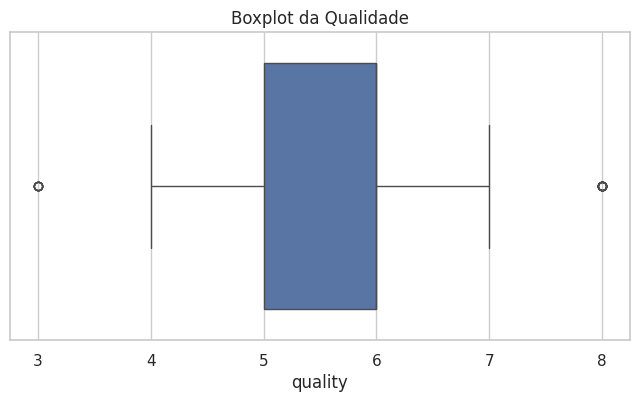

In [64]:
fig, axes = plt.subplots(figsize=(8,4))
sns.boxplot(x="quality", data=df)
axes.set_title('Boxplot da Qualidade')
plt.show()

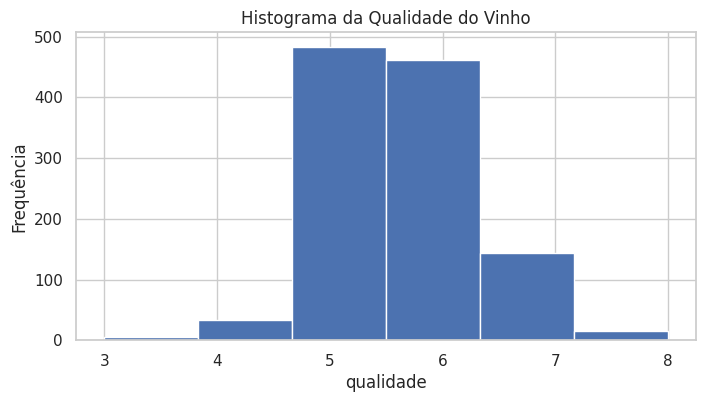

In [65]:
plt.figure(figsize=(8, 4))
plt.hist(df['quality'], bins=6)
plt.ylabel('Frequência')
plt.xlabel('qualidade')
plt.title('Histograma da Qualidade do Vinho')
plt.show()

Análise: A variável target "Quality" apresenta poucos outliers, com dados concentrados nas notas 5 e 6. No entanto, há um grande desbalanceamento entre as classes, onde apenas 14% dos dados apresentam classificação alta do vinho, enquanto 86% apresentam classificação média/baixa.

### 3.2 Análise das Variáveis Numéricas

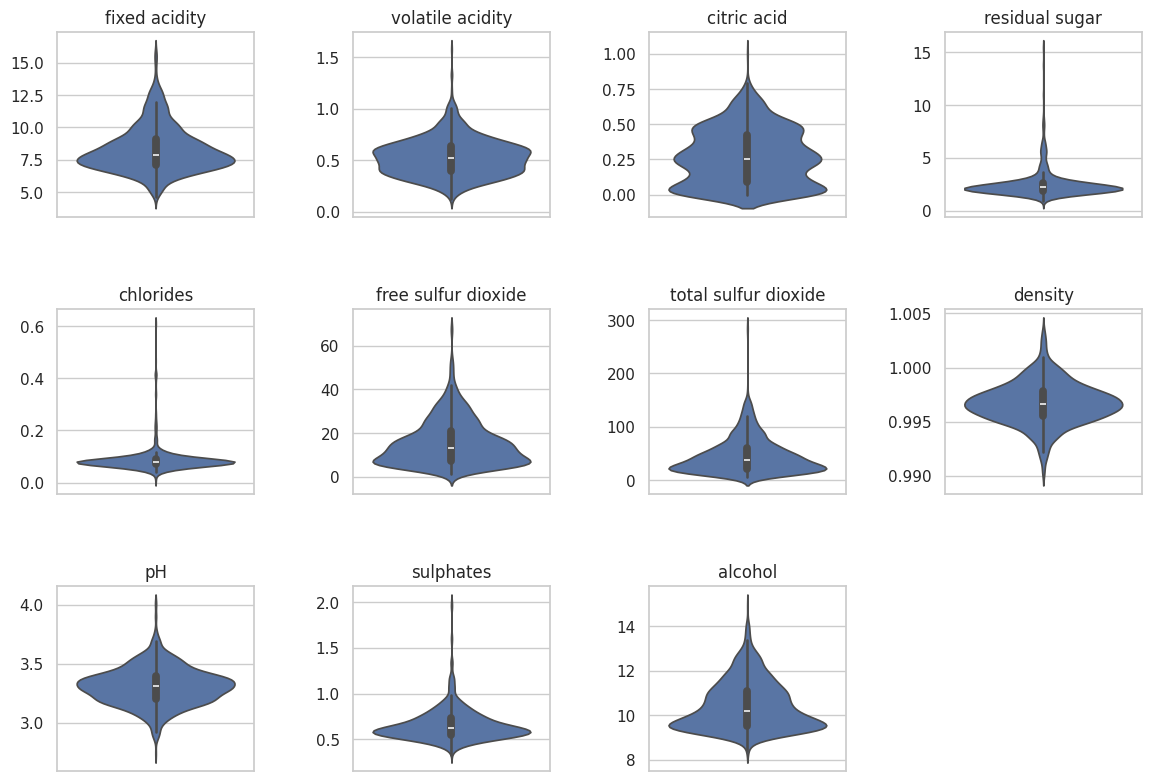

In [66]:
cols = df.select_dtypes('number').columns.drop(['quality', 'quality_bin'], errors='ignore')

n = len(cols)
ncols = 4
nrows = -(-n // ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows))

for ax, col in zip(axes.flat, cols):
    sns.violinplot(y=df[col], inner='box', ax=ax)
    ax.set_title(col)
    ax.set_ylabel('')

for ax in axes.flat[n:]:
    ax.set_visible(False)

fig.subplots_adjust(wspace=0.5, hspace=0.5)
plt.show()

Análise: Os violin plots mostram que a maior parte dos valores está concentrada em faixas específicas para cada variável, indicando distribuições relativamente estáveis. Observam-se alguns valores extremos principalmente em residual sugar, total sulfur dioxide, chlorides e sulphates, evidenciando a presença de vinhos com características químicas mais distintas. Já variáveis como density, pH e fixed acidity apresentam distribuições mais concentradas e menor ocorrência de valores extremos.

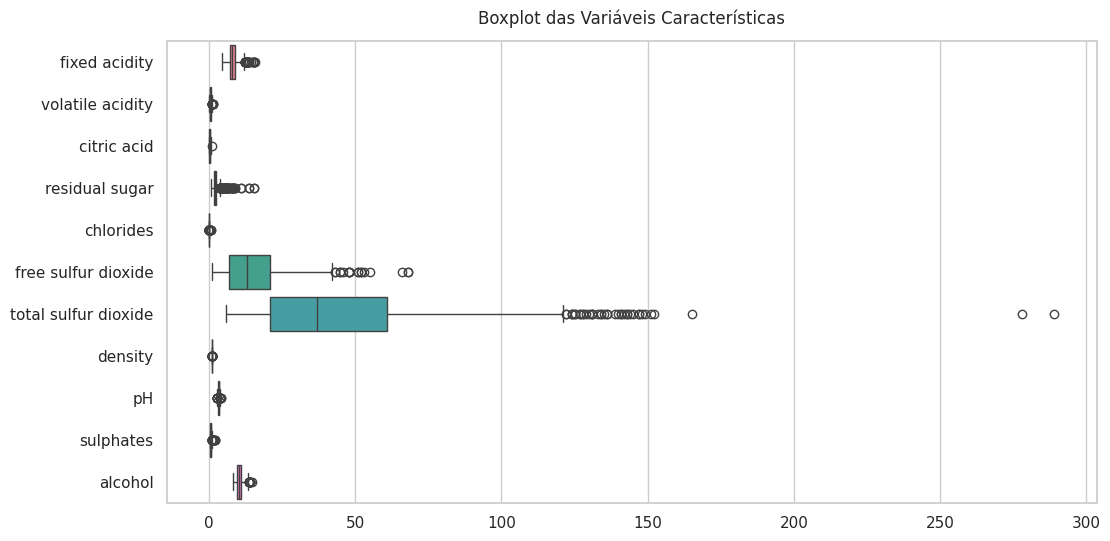

In [67]:
cols = df.select_dtypes('number').columns.drop(['quality', 'quality_bin'], errors='ignore')

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[cols], orient='h')
plt.title('Boxplot das Variáveis Características', fontsize=12, pad=12)
plt.show()

In [68]:
features = [c for c in df.columns
            if c not in ['quality', 'quality_bin']]

q1 = df[features].quantile(0.25)
q3 = df[features].quantile(0.75)
iqr = q3 - q1

lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

mascara = (df[features] < lim_inf) | (df[features] > lim_sup)

resumo = pd.DataFrame({
    'Q1': q1, 'Q3': q3, 'IQR': iqr,
    'limite_inferior': lim_inf, 'limite_superior': lim_sup,
    'qtd_outliers': mascara.sum(),
    'pct_outliers': (mascara.mean() * 100).round(1)
}).sort_values('qtd_outliers', ascending=False)

resumo.round(3)

,Q1,Q3,IQR,limite_inferior,limite_superior,qtd_outliers,pct_outliers
residual sugar,1.900,2.600,0.700,0.850,3.650,110,9.6
chlorides,0.070,0.090,0.020,0.040,0.120,77,6.7
fixed acidity,7.100,9.100,2.000,4.100,12.100,44,3.8
sulphates,0.550,0.730,0.180,0.280,1.000,43,3.8
total sulfur dioxide,21.000,61.000,40.000,-39.000,121.000,40,3.5
density,0.996,0.998,0.002,0.992,1.001,36,3.1
pH,3.205,3.400,0.195,2.913,3.692,20,1.7
free sulfur dioxide,7.000,21.000,14.000,-14.000,42.000,18,1.6
volatile acidity,0.392,0.640,0.248,0.021,1.011,14,1.2
alcohol,9.500,11.100,1.600,7.100,13.500,12,1.0


**Identificação de Outliers**

A análise de outliers foi realizada utilizando o método do Intervalo Interquartil (IQR). Os resultados mostram que a maior concentração de valores extremos está nas variáveis residual sugar (9,6%) e chlorides (6,7%), enquanto as demais apresentaram percentuais relativamente baixos.  

De forma geral, esses valores não parecem indicar erros de coleta ou registros inconsistentes. Pelo contrário, eles provavelmente refletem a diversidade dos vinhos presentes na base, que podem possuir composições químicas bastante diferentes entre si.  

Remover esses valores poderia significar a perda de informações importantes sobre vinhos com características mais raras, mas que ajudam a explicar diferenças de qualidade.  

Em resumo, foram identificados outliers em várias variáveis físico-químicas, principalmente relacionadas ao açúcar residual, cloretos e acidez. No entanto, eles foram considerados representativos da variabilidade natural dos vinhos e não justificaram a remoção de observações da base.

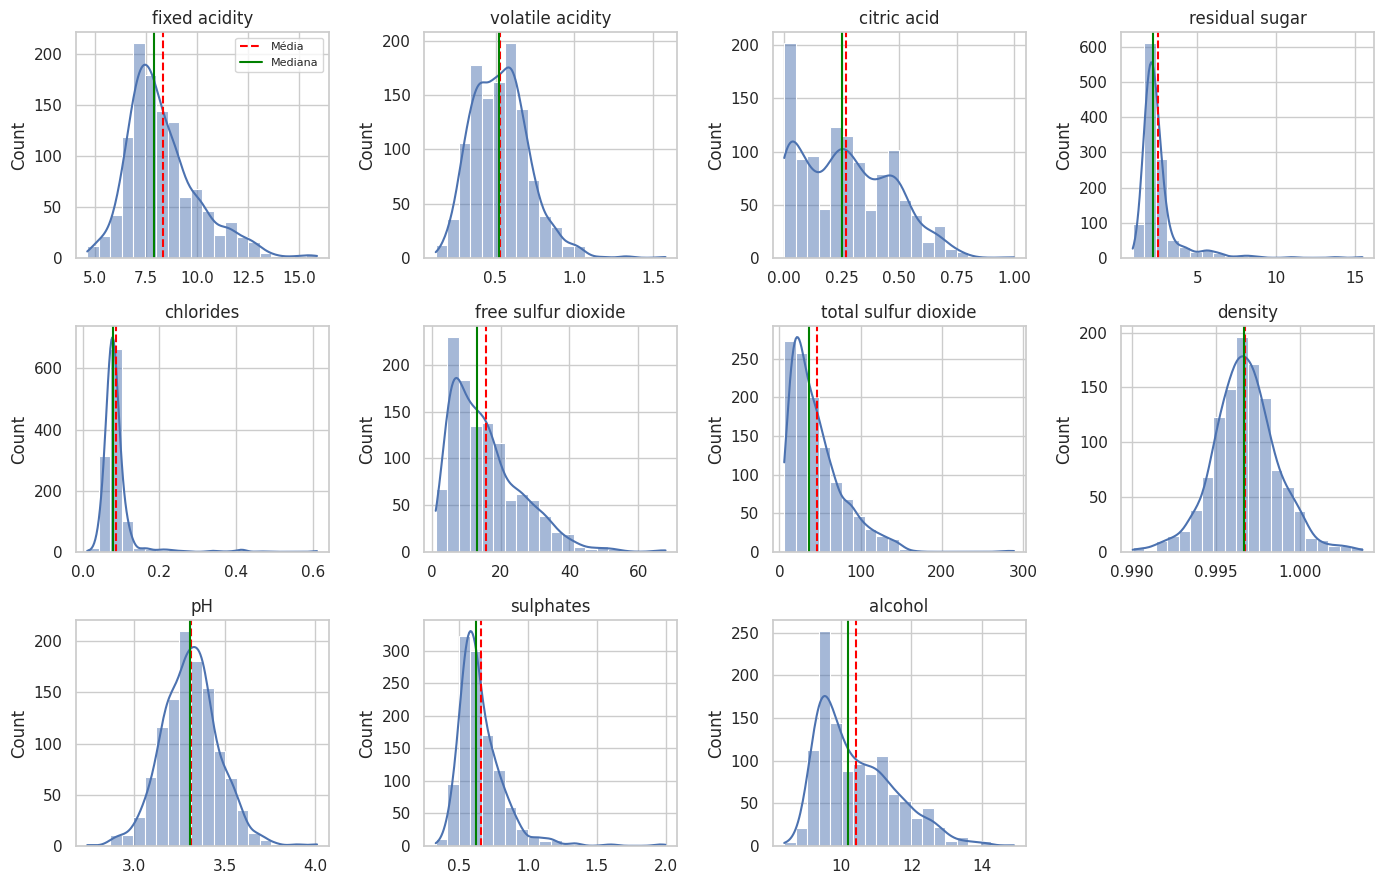

In [69]:
n = len(cols)
ncols = 4
nrows = -(-n // ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3 * nrows))

for ax, col in zip(axes.flat, cols):
    sns.histplot(data=df, x=col, bins=20, kde=True, ax=ax,
                 line_kws={'color': 'black', 'linewidth': 1.5})

    ax.axvline(df[col].mean(),   color='red',   linestyle='--', label='Média')
    ax.axvline(df[col].median(), color='green', linestyle='-',  label='Mediana')

    ax.set_title(col)
    ax.set_xlabel('')
    if col == cols[0]:
        ax.legend(fontsize=8)

for ax in axes.flat[n:]:
    ax.set_visible(False)

fig.tight_layout()
plt.show()

Análise:  As variáveis Density e pH apresentam distribuições aproximadamente simétricas, com média e mediana muito próximas. Já Alcohol, Fixed Acidity, Volatile Acidity e Citric Acid exibem assimetria positiva moderada, com a média ligeiramente acima da mediana. As variáveis Residual Sugar, Chlorides, Sulphates, Free Sulfur Dioxide e Total Sulfur Dioxide possuem forte assimetria à direita, evidenciada por caudas longas e médias superiores às medianas, indicando a presença de valores extremos elevados.


### 3.3 Correlação entre as Variáveis

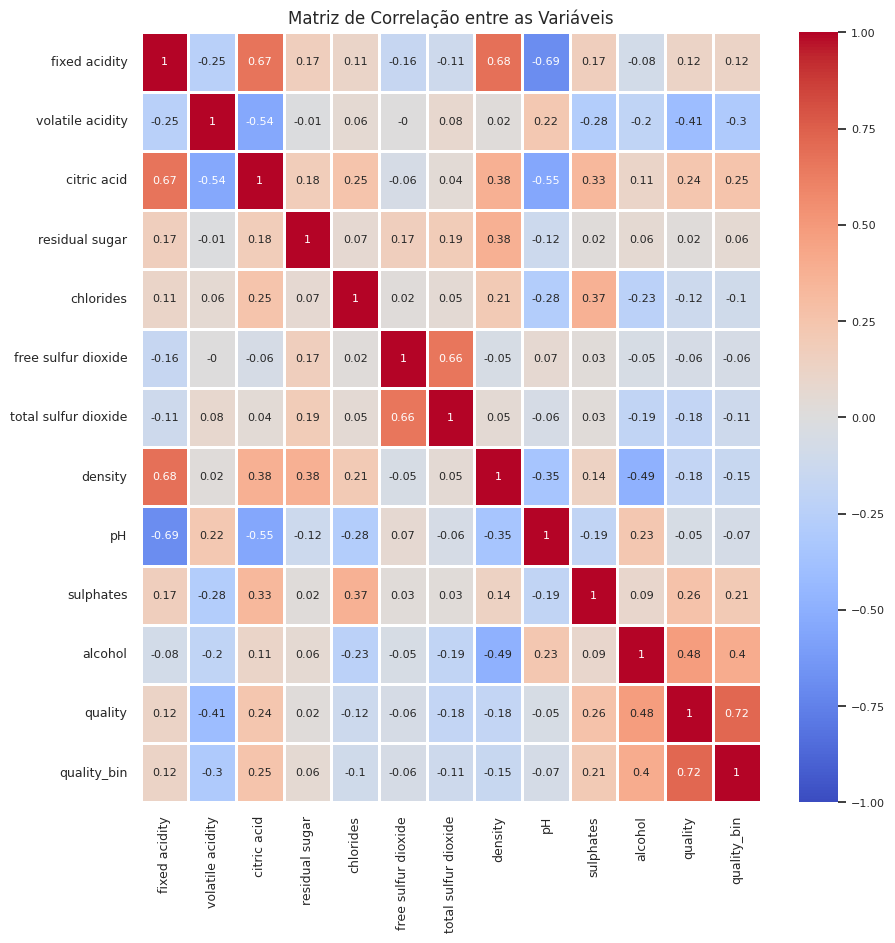

In [70]:
correlacao_matriz = df.corr(numeric_only=True).round(2)

fig, ax = plt.subplots(figsize=(10, 10))

sns.heatmap(
    data=correlacao_matriz,
    annot=True,
    annot_kws={'size':8},
    linewidths=1,
    ax=ax,
    cmap='coolwarm',
    vmin=-1, vmax=1
)

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=8)

ax.tick_params(axis='both',labelsize=9)
ax.set_title('Matriz de Correlação entre as Variáveis')
plt.show()

### 3.4 Relação de cada variável com a alta qualidade

A relação foi avaliada pela correlação de Pearson com a variável alvo, usando a classificação: |r| de 0,9 a 1 muito forte; de 0,7 a 0,9 forte; de 0,5 a 0,7 moderada; de 0,3 a 0,5 fraca; de 0 a 0,3 não possui correlação. A mediana de cada variável nas duas classes complementa a análise.

| Variável | Correlação | Classificação | Mediana (baixa/média → alta) |
| --- | --- | --- | --- |
| alcohol | +0,40 | fraca | 10,0 → 11,6 |
| volatile acidity | −0,30 | fraca (limite da faixa) | 0,55 → 0,36 |
| citric acid | +0,25 | não possui correlação | 0,24 → 0,41 |
| sulphates | +0,21 | não possui correlação | 0,60 → 0,74 |
| density | −0,15 | não possui correlação | 0,9968 → 0,9957 |
| fixed acidity | +0,12 | não possui correlação | 7,8 → 8,7 |
| total sulfur dioxide | −0,11 | não possui correlação | 39 → 28 |
| chlorides | −0,10 | não possui correlação | 0,080 → 0,073 |
| pH | −0,07 | não possui correlação | 3,315 → 3,270 |
| residual sugar | +0,06 | não possui correlação | 2,2 → 2,3 |
| free sulfur dioxide | −0,06 | não possui correlação | 14 → 12 |

  

* **Álcool (+0,40):** é a maior correlação da base. Vinhos de alta qualidade têm mais álcool, mas os dados mostram associação, não a causa.
* **Acidez volátil (−0,30):** está no limite inferior da faixa. Representa o ácido acético, que em excesso dá gosto de vinagre e indica deterioração.

* **Ácido cítrico (+0,25) e sulfatos (+0,21):** são as mais próximas da faixa fraca, e as medianas são maiores na classe de alta qualidade. O ácido cítrico é associado a frescor e sabor (e 95 dos 99 zeros estão na classe de baixa/média qualidade). Os sulfatos podem contribuir para o dióxido de enxofre, conservante (hipótese não testada). Ainda assim, a relação linear com a qualidade é pequena.
* **Demais variáveis (acidez fixa, açúcar residual, densidade, dióxido de enxofre total e livre, cloretos e pH):** sem correlação relevante. A densidade provavelmente reflete o álcool (correlação de −0,49 entre os dois), o que não foi testado.

**Conclusão:** nenhuma variável passa da correlação fraca. Apenas o álcool (+) e a acidez volátil (−) atingem essa faixa, e as demais não têm correlação linear relevante com a alta qualidade. Correlação não implica causalidade.



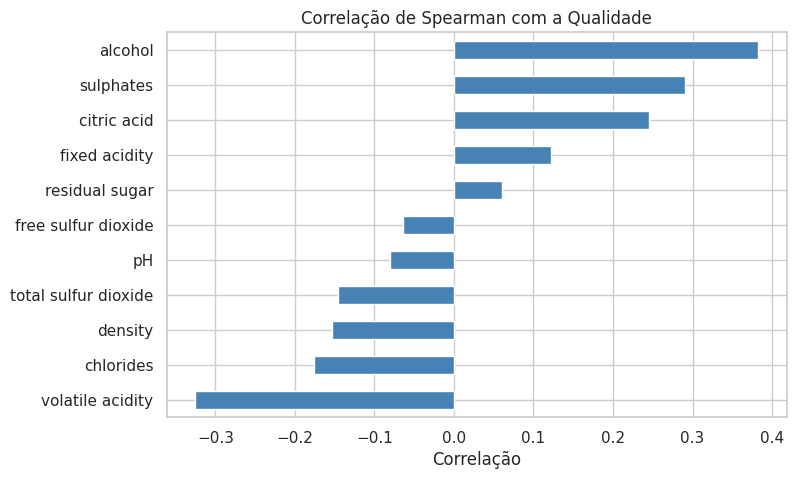

In [71]:
correl = (df.select_dtypes('number')
          .corr(method='spearman')['quality_bin']
          .drop(['quality', 'quality_bin'], errors='ignore')
          .sort_values())

plt.figure(figsize=(8, 5))
correl.plot(kind='barh', color='steelblue')
plt.title('Correlação de Spearman com a Qualidade')
plt.xlabel('Correlação')
plt.show()

top = correl.sort_values(ascending=False).head(5).index

### 3.5 Variáveis que apresentam correlação positiva com a variável target

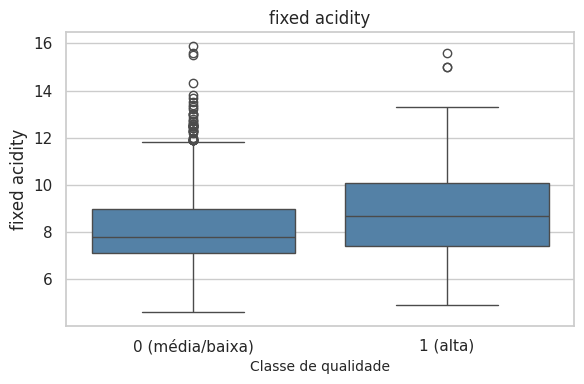

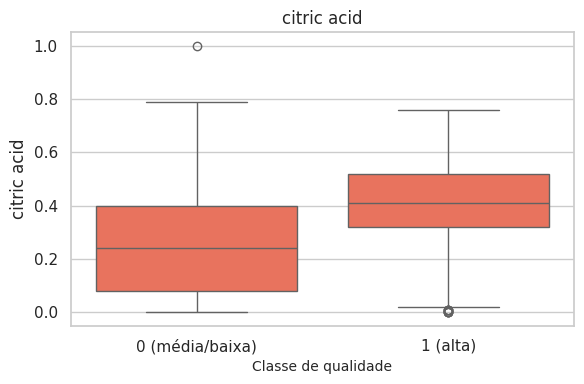

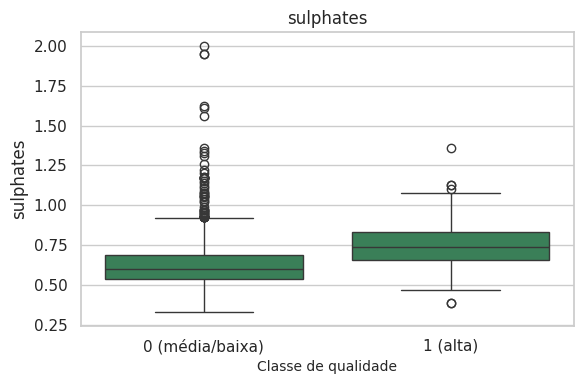

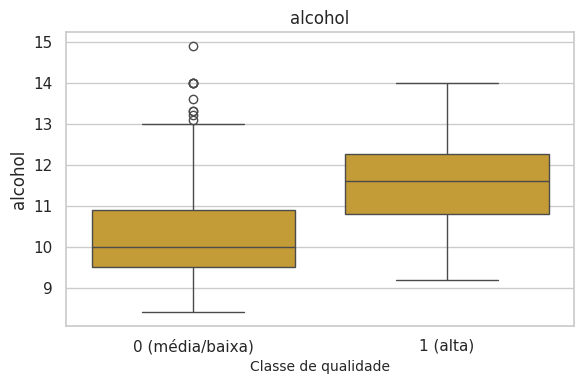

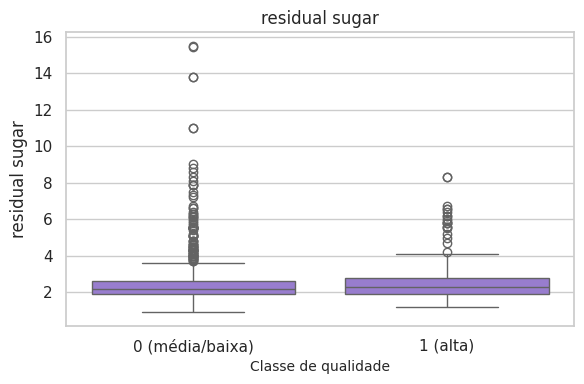

In [72]:
vars_ = ['fixed acidity', 'citric acid', 'sulphates', 'alcohol', 'residual sugar']

cores = ['steelblue', 'tomato', 'seagreen', 'goldenrod', 'mediumpurple']


for var, cor in zip(vars_, cores):
    plt.figure(figsize=(6, 4))
    ax = sns.boxplot(x='quality_bin', y=var, data=df, whis=1.5, color=cor)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['0 (média/baixa)', '1 (alta)'])
    ax.set_xlabel('Classe de qualidade', fontsize=10)
    ax.set_title(f'{var}')
    plt.tight_layout()
    plt.show()


Análise: As variáveis Fixed Acidity, Citric Acid, Sulphates, Alcohol e Residual Sugar apresentaram correlações positivas com a variável alvo (quality_bin). A partir dos boxplots, observa-se que os vinhos classificados como de alta qualidade tendem a apresentar valores mais elevados dessas variáveis, principalmente de álcool e sulfatos. Além disso, a classe de alta qualidade apresentou poucos outliers relevantes, indicando um comportamento mais homogêneo entre os vinhos bem avaliados. Os outliers identificados parecem representar características específicas de alguns vinhos e não evidenciam inconsistências nos dados.

# 4. Desenvolvimento dos Modelos

Os modelos foram testados em duas partes.  
Na primeira, nomeada como "Full", foi considerado o dataset total.  
Na segunda, nomeada como "Top5", foram consideradas apenas as variáveis que apresentam correlação positiva com a variável target - 'quality_bin'.

### 4.1 Separação das variáveis

In [73]:
X_full = df.drop(['quality', 'quality_bin'], axis=1)
y = df['quality_bin']

In [74]:
corr = (df.select_dtypes('number')
         .corr(method='spearman')['quality_bin']
         .drop(['quality', 'quality_bin'], errors='ignore')
         .sort_values())

top5 = corr.sort_values(ascending=False).head(5).index

X_top5 = X_full[top5]

print('Top 5 variáveis selecionadas:', list(top5))

Top 5 variáveis selecionadas: ['alcohol', 'sulphates', 'citric acid', 'fixed acidity', 'residual sugar']


### 4.2 Divisão da base

In [75]:
Xf_train, Xf_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.20, random_state=42, stratify=y
)

Xt_train, Xt_test, _, _= train_test_split(
    X_top5, y, test_size=0.20, random_state=42, stratify=y
    )

### 4.3 Normalização das variáveis numéricas

In [76]:
scaler_full = StandardScaler()
Xf_train_scaled = scaler_full.fit_transform(Xf_train)
Xf_test_scaled = scaler_full.transform(Xf_test)

scaler_top5 = StandardScaler()
Xt_train_scaled = scaler_top5.fit_transform(Xt_train)
Xt_test_scaled = scaler_top5.transform(Xt_test)

### 4.4 Balanceamento das classes

In [77]:
smote = SMOTE(random_state=42)

Xf_train_res, y_train_res = smote.fit_resample(Xf_train_scaled, y_train)
Xt_train_res, y_train_res2 = smote.fit_resample(Xt_train_scaled, y_train)

### 4.5 Desenvolvimento dos modelos

In [78]:
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=500),
    'SVM': SVC(kernel='rbf', class_weight='balanced', probability=True),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)
}

results = {'full': {}, 'top5': {}}

In [79]:
for name, model in models.items():

  # Modelo com todas as variáveis
  model.fit(Xf_train_res, y_train_res)
  y_pred_f = model.predict(Xf_test_scaled)
  y_prob_f = model.predict_proba(Xf_test_scaled)[:, 1]

  results['full'][name] = {
      'ROC-AUC': roc_auc_score(y_test, y_prob_f),
      'F1': f1_score(y_test, y_pred_f)
  }


  # Modelo com Top5 variáveis
  model.fit(Xt_train_res, y_train_res2)
  y_pred_t = model.predict(Xt_test_scaled)
  y_prob_t = model.predict_proba(Xt_test_scaled)[:, 1]

  results["top5"][name] = {
        "ROC-AUC": roc_auc_score(y_test, y_prob_t),
        "F1": f1_score(y_test, y_pred_t)
    }

In [80]:
print("RESULTADOS COM TODAS AS VARIÁVEIS\n")
for model, metrics in results["full"].items():
    print(f"{model}: ROC-AUC={metrics['ROC-AUC']:.3f} | F1={metrics['F1']:.3f}")

print('\n')

print("RESULTADOS COM APENAS TOP 5 VARIÁVEIS\n")
for model, metrics in results["top5"].items():
    print(f"{model}: ROC-AUC={metrics['ROC-AUC']:.3f} | F1={metrics['F1']:.3f}")

RESULTADOS COM TODAS AS VARIÁVEIS

Logistic Regression: ROC-AUC=0.848 | F1=0.467
SVM: ROC-AUC=0.871 | F1=0.532
Random Forest: ROC-AUC=0.909 | F1=0.606


RESULTADOS COM APENAS TOP 5 VARIÁVEIS

Logistic Regression: ROC-AUC=0.801 | F1=0.447
SVM: ROC-AUC=0.816 | F1=0.500
Random Forest: ROC-AUC=0.856 | F1=0.537


Para avaliar os modelos foram utilizadas as métricas:  

*   ROC-AUC: mede a capacidade do modelo em distinguir vinhos de alta qualidade dos demais. Quanto mais próximo de 1, melhor.  

*   F1-Score: média harmônica entre Precisão e Recall. É especialmente importante, pois a classe "Alta Qualidade" é minoritária.



In [81]:
metricas = pd.concat({c: pd.DataFrame(r).T for c, r in results.items()})
metricas = metricas.round(3)
metricas.index.names = ['Cenario', 'Modelo']
metricas.to_csv(f'{PASTA_RESULTS}/metricas_modelos.csv')

### 4.6 Comparação dos Modelos  

### a) Logistic Regression  

A Regressão Logística apresentou o menor desempenho entre os modelos avaliados.


* Com todas as variáveis:

ROC-AUC = 0,848
F1 = 0,467

* Com Top 5 variáveis:

ROC-AUC = 0,801
F1 = 0,447

A redução das variáveis impactou negativamente o desempenho, indicando que o modelo linear depende de informações adicionais presentes nas demais características físico-químicas.

* Vantagens:

Fácil interpretação.
Baixo custo computacional.

* Desvantagens:

Dificuldade em capturar relações não lineares entre atributos químicos e qualidade.  




### b) SVM  

O SVM apresentou desempenho superior à Regressão Logística.  

*  Com todas as variáveis:

ROC-AUC = 0,871
F1 = 0,532

*  Com Top 5 variáveis:

ROC-AUC = 0,816
F1 = 0,500

O modelo conseguiu lidar melhor com as relações entre as variáveis, porém também apresentou perda de desempenho quando algumas características foram removidas.

*  Vantagens:

Boa capacidade de generalização.
Capta padrões mais complexos.

*  Desvantagens:

Menor interpretabilidade.
Maior custo computacional.  

### c) Random Forest  

O Random Forest apresentou os melhores resultados em ambos os experimentos.

* Com todas as variáveis:

ROC-AUC = 0,909
F1 = 0,606

* Com Top 5 variáveis:

ROC-AUC = 0,856
F1 = 0,537

Mesmo utilizando apenas cinco variáveis, o modelo manteve desempenho elevado, demonstrando robustez e capacidade de capturar relações não lineares entre os atributos físico-químicos.

* Vantagens:

Melhor capacidade preditiva.
Menor sensibilidade a ruídos e outliers.
Captura interações complexas entre variáveis.

* Desvantagens:

Interpretação menos intuitiva em comparação à Regressão Logística.

### 4.7 Avaliação dos Modelos

Comparando o melhor modelo (Random Forest):  


| Cenário            | ROC-AUC | F1    |
| ------------------ | ------- | ----- |
| Todas as variáveis | 0,909   | 0,606 |
| Top 5 variáveis    | 0,856   | 0,537 |  
  
  
  
Diferença observada:

ROC-AUC: queda de aproximadamente 5,8%
F1-Score: queda de aproximadamente 11,4%

Isso mostra que as cinco variáveis mais correlacionadas possuem grande poder explicativo, porém parte da informação preditiva ainda está presente nas demais variáveis do dataset.


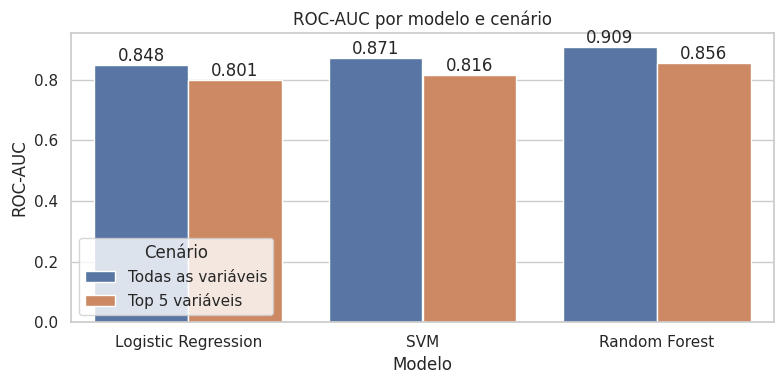

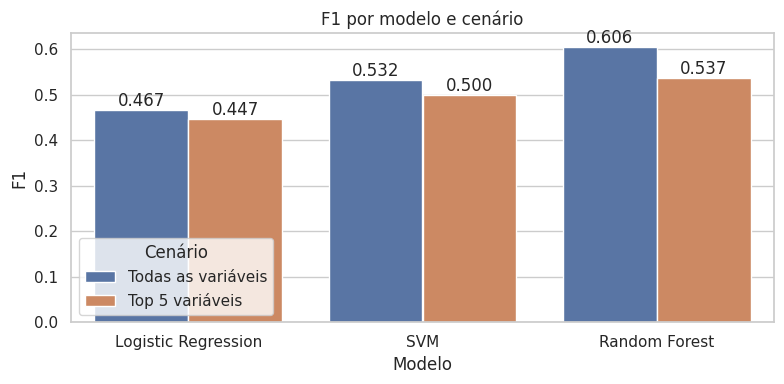

In [89]:
tabela = pd.concat({c: pd.DataFrame(r).T for c, r in results.items()}).reset_index()
tabela.columns = ['Cenário', 'Modelo', 'ROC-AUC', 'F1']
tabela['Cenário'] = tabela['Cenário'].map({'full': 'Todas as variáveis', 'top5': 'Top 5 variáveis'})

for metrica in ['ROC-AUC', 'F1']:
    plt.figure(figsize=(8, 4))
    ax = sns.barplot(data=tabela, x='Modelo', y=metrica, hue='Cenário')
    for c in ax.containers:
        ax.bar_label(c, fmt='%.3f')
    ax.set_title(f'{metrica} por modelo e cenário')
    plt.tight_layout()
    plt.savefig(f"{PASTA_RESULTS}/barras_{metrica.replace(' ', '_')}.png",
                dpi=150, bbox_inches='tight')
    plt.show()

Os resultados demonstram que:

Random Forest foi o melhor modelo, alcançando ROC-AUC de 0,909 e F1-Score de 0,606.

SVM apresentou desempenho intermediário, superando a Regressão Logística.

Regras lineares não foram suficientes para capturar completamente a relação entre os atributos químicos e a qualidade do vinho.

A utilização apenas das cinco variáveis mais correlacionadas reduziu o desempenho dos modelos, mas manteve resultados satisfatórios, indicando que:

Alcohol,
Sulphates,
Citric Acid,
Fixed Acidity,
Residual Sugar

concentram uma parcela significativa da informação necessária para prever a qualidade do vinho.

Portanto, para fins preditivos, o Random Forest treinado com todas as variáveis é a alternativa mais recomendada, enquanto o modelo com apenas as cinco variáveis representa uma solução mais simples e com perda relativamente moderada de desempenho.

### 4.8 Matriz de Confusão

<Figure size 400x400 with 0 Axes>

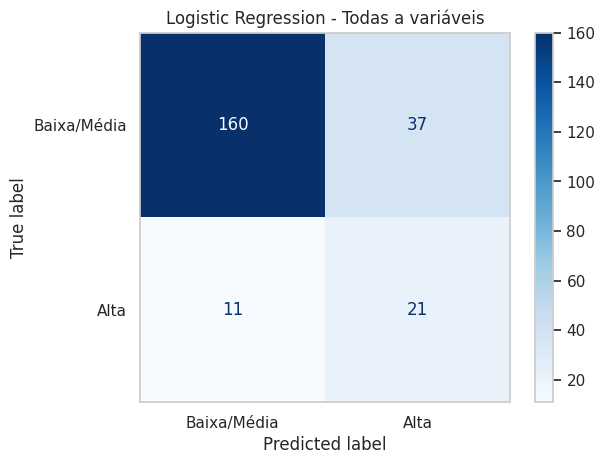

<Figure size 400x400 with 0 Axes>

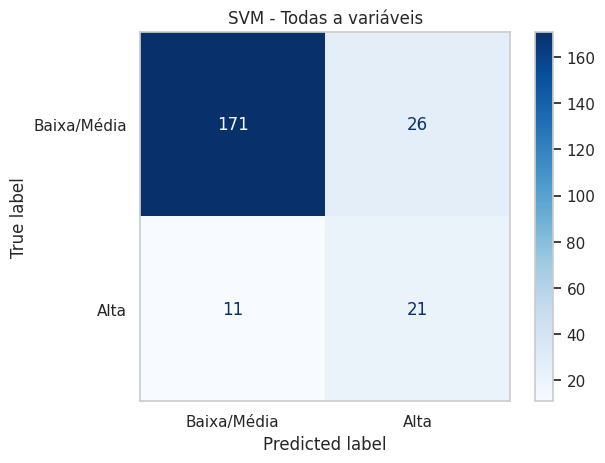

<Figure size 400x400 with 0 Axes>

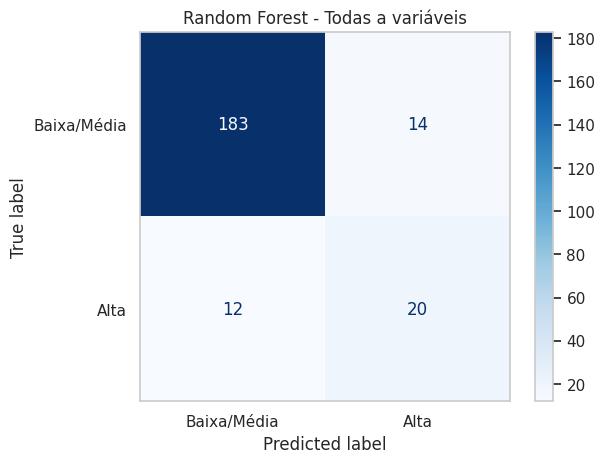

<Figure size 400x400 with 0 Axes>

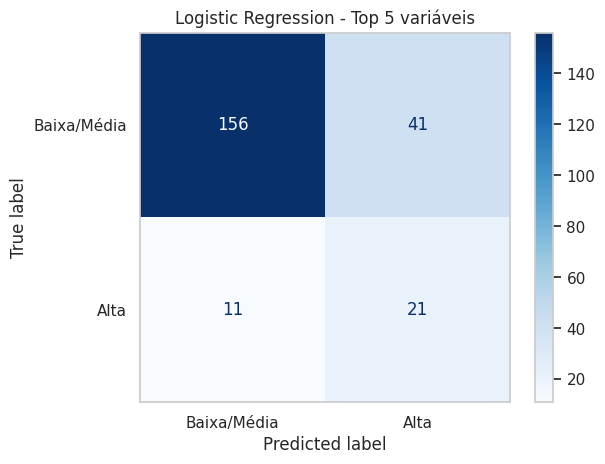

<Figure size 400x400 with 0 Axes>

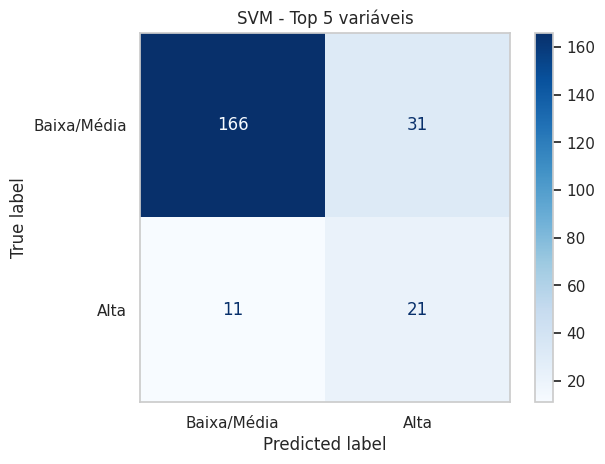

<Figure size 400x400 with 0 Axes>

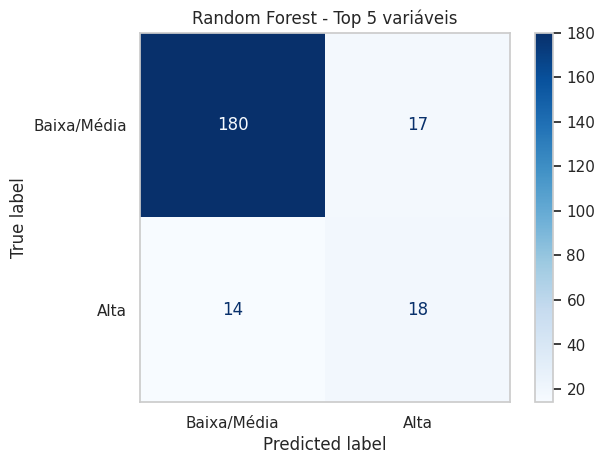

In [88]:
cenarios = {
    'Todas a variáveis': (Xf_train_res, y_train_res, Xf_test_scaled),
    'Top 5 variáveis': (Xt_train_res, y_train_res2, Xt_test_scaled)
}

for nome_cenario, (X_tr, y_tr, X_te) in cenarios.items():
  for nome_modelo, modelo in models.items():

    modelo.fit(X_tr, y_tr)
    y_predito = modelo.predict(X_te)

    matriz_confusao = confusion_matrix(y_true = y_test,
                                       y_pred = y_predito,
                                       labels=[0,1])

    figure = plt.figure(figsize=(4,4))
    disp = ConfusionMatrixDisplay(confusion_matrix=matriz_confusao,
                                  display_labels=['Baixa/Média', 'Alta'])

    disp.plot(values_format='d', cmap='Blues')
    plt.grid(False)
    plt.title(f'{nome_modelo} - {nome_cenario}')
    plt.savefig(f"{PASTA_RESULTS}/cm_{nome_modelo.replace(' ', '_')}_{nome_cenario.split()[0]}.png",
                dpi=150, bbox_inches='tight')
    plt.show()

Análise: A Matriz de Confusão reforça a escolha, os três modelos identificam um número parecido de vinhos de alta qualidade (20 a 21 dos 32 do teste), mas o Random Forest para todas as variáveis gera menos falsos positivos (14, contra 26 do SVM e 37 da Regressão Logística). Ou seja, sua vantagem está na precisão das previsões de alta qualidade, e não na quantidade de vinhos bons encontrados.

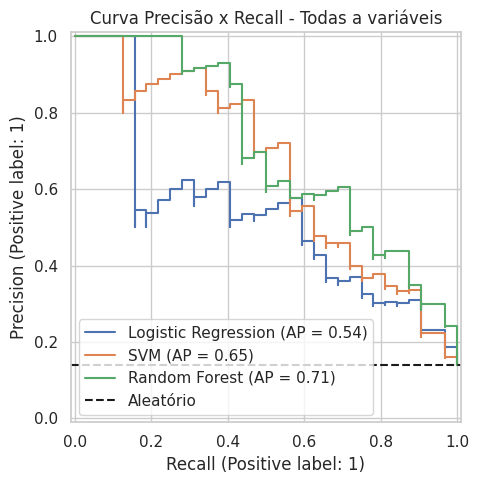

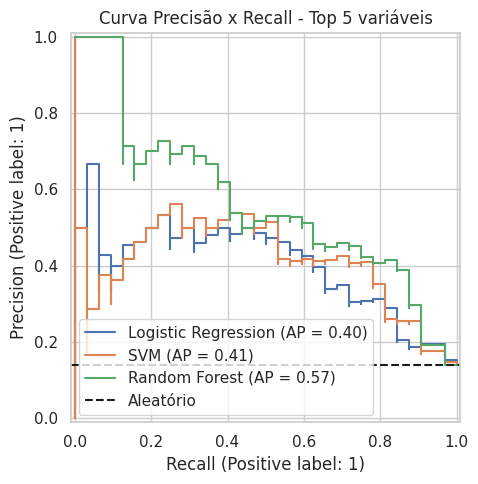

In [92]:
# 4.9 Curva Precisao x Recall

aps = {}
for nome_cenario, (X_tr, y_tr, X_te) in cenarios.items():
    fig, ax = plt.subplots(figsize=(7, 5))
    for nome_modelo, modelo in models.items():
        modelo.fit(X_tr, y_tr)
        PrecisionRecallDisplay.from_estimator(modelo, X_te, y_test, name=nome_modelo, ax=ax)
        aps[(nome_cenario, nome_modelo)] = average_precision_score(y_test, modelo.predict_proba(X_te)[:, 1])
    ax.axhline(y_test.mean(), color='k', linestyle='--', label='Aleatório')
    ax.set_title(f'Curva Precisão x Recall - {nome_cenario}')
    ax.legend(loc='lower left')
    plt.tight_layout()
    plt.savefig(f"{PASTA_RESULTS}/pr_{nome_cenario.split()[0]}.png", dpi=150, bbox_inches='tight')
    plt.show()

# 5. Interpretação dos Resultados

### 5.1 Variáveis com maior influência na qualidade do vinho

Com base na matriz de correlação, as variáveis mais relacionadas à qualidade do vinho foram:

*   Alcohol: variável com maior influência positiva. Vinhos com maior teor alcoólico tendem a apresentar melhor qualidade.  
*   Sulphates: contribuem para a conservação e estabilidade do vinho, estando associados a avaliações mais altas.  
*   Citric Acid: relacionada ao frescor e equilíbrio sensorial.
*   Fixed Acidity: ajuda na estrutura e estabilidade do vinho.  
*   Residual Sugar: apresentou influência positiva, contribuindo para o equilíbrio do sabor.   

Além disso, variáveis como volatile acidity e chlorides apresentaram influência negativa, indicando que valores elevados podem reduzir a qualidade percebida.

### 5.2 Implicações para o processo de produção

Os resultados sugerem que a vinícola deve concentrar esforços em:  

*   Controlar o processo de fermentação para alcançar níveis adequados de álcool.  
*   Monitorar e ajustar os níveis de sulfatos para garantir estabilidade e conservação.  
*   Manter o equilíbrio da acidez (ácido cítrico e acidez fixa), contribuindo para melhor perfil sensorial.  
*   Controlar o açúcar residual de acordo com o estilo desejado do vinho.  
*   Reduzir a acidez volátil, evitando defeitos associados a oxidação e contaminações microbiológicas.   

Em resumo, os fatores mais importantes para a obtenção de vinhos de alta qualidade foram teor alcoólico, sulfatos e equilíbrio químico da acidez, mostrando-se pontos críticos para o controle do processo produtivo.

In [91]:
  # !zip -r results.zip results
  # from google.colab import files
  # files.download('results.zip')

updating: results/ (stored 0%)
updating: results/cm_SVM_Top.png (deflated 16%)
updating: results/cm_Random_Forest_Top.png (deflated 16%)
updating: results/cm_SVM_Todas.png (deflated 16%)
updating: results/barras_ROC-AUC.png (deflated 13%)
updating: results/cm_Logistic_Regression_Todas.png (deflated 15%)
updating: results/cm_Random_Forest_Todas.png (deflated 15%)
updating: results/metricas_modelos.csv (deflated 35%)
updating: results/cm_Logistic_Regression_Top.png (deflated 15%)
updating: results/barras_F1.png (deflated 13%)
  adding: results/pr_Todas.png (deflated 11%)
  adding: results/pr_Top.png (deflated 11%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>